# Klasifikasi Biner - Dokumentasi 3 Dataset

**Definisi:** target hanya memiliki **2 kelas**, dan setiap data hanya masuk ke satu kelas.

| No | Dataset | Sumber |
|---|---|---|
| 1 | Heart Failure Prediction | Kaggle (fedesoriano) |
| 2 | Stroke Prediction Dataset | Kaggle (fedesoriano) |
| 3 | Telco Customer Churn | Kaggle (blastchar), asal IBM Sample Data |

**Cara pakai:** unduh 3 file CSV dari Kaggle (perlu login), lalu jalankan notebook. Di Google Colab, notebook akan meminta Anda mengunggah file tiap dataset.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, io, os
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 160)

def muat_csv(nama_file, **kw):
    """Baca CSV lokal; jika tidak ada dan berjalan di Colab, minta upload file."""
    if os.path.exists(nama_file):
        return pd.read_csv(nama_file, **kw)
    try:
        from google.colab import files
        print(f"Upload file: {nama_file}")
        up = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(up.values()))), **kw)
    except ImportError:
        raise FileNotFoundError(f"Letakkan {nama_file} di folder yang sama dengan notebook ini.")

def analisis_single_label(nama, y, nama_kelas=None):
    y = pd.Series(np.asarray(y).ravel()).reset_index(drop=True)
    vc = y.value_counts().sort_index()
    if nama_kelas is not None:
        vc.index = [nama_kelas.get(i, i) for i in vc.index]
    persen = (vc / vc.sum() * 100).round(2)
    tabel = pd.DataFrame({"Jumlah": vc, "Persentase (%)": persen})
    rin = {"Dataset": nama, "Jumlah Data": int(vc.sum()), "Jumlah Kelas": int(len(vc)),
           "Kelas Mayoritas (%)": float(persen.max()), "Kelas Minoritas (%)": float(persen.min()),
           "Imbalance Ratio": round(vc.max() / vc.min(), 2),
           "Tipe Terdeteksi": "Biner" if len(vc) == 2 else ("Multikelas" if len(vc) > 2 else "Satu kelas")}
    return tabel, rin

def analisis_multilabel(nama, Y, nama_label):
    Y = np.asarray(Y).astype(int); n, L = Y.shape; pb = Y.sum(axis=1); card = pb.mean()
    tabel = pd.DataFrame({"Jumlah": Y.sum(axis=0), "Persentase (%)": (Y.mean(axis=0) * 100).round(2)}, index=list(nama_label))
    rin = {"Dataset": nama, "Jumlah Data": n, "Jumlah Label": L,
           "Label Cardinality": round(card, 3), "Label Density": round(card / L, 3),
           "% Data 0 Label": round((pb == 0).mean() * 100, 2), "% Data 1 Label": round((pb == 1).mean() * 100, 2),
           "% Data >1 Label (Multilabel)": round((pb > 1).mean() * 100, 2), "Maks Label per Data": int(pb.max()),
           "Tipe Terdeteksi": "Multilabel" if (pb > 1).any() else "Bukan multilabel"}
    return tabel, rin

def plot_bar(ax, tabel, judul, horizontal=False):
    s = tabel["Persentase (%)"]
    (s.plot(kind="barh", ax=ax, color="steelblue") if horizontal else s.plot(kind="bar", ax=ax, color="steelblue"))
    ax.set_title(judul); (ax.set_xlabel if horizontal else ax.set_ylabel)("Persentase (%)")

## 1. Heart Failure Prediction
- **Sumber:** https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction
- **Pembuat:** fedesoriano (2021), hasil penggabungan lima dataset penyakit jantung dari UCI
- **Deskripsi:** data klinis pasien untuk memprediksi penyakit jantung
- **Jumlah data:** 918 | **Fitur:** 11 fitur klinis
- **Target:** `HeartDisease` (0 = tidak, 1 = ya) -> **2 kelas**
- **File yang diunggah:** `heart.csv`

In [2]:
df_heart = muat_csv("heart.csv")
print(df_heart.shape); display(df_heart.head(3))
tab_heart, rin_heart = analisis_single_label("Heart Failure", df_heart["HeartDisease"], {0: "Tidak (0)", 1: "Ya (1)"})
display(tab_heart)

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0


,Jumlah,Persentase (%)
Tidak (0),410,44.66
Ya (1),508,55.34


## 2. Stroke Prediction Dataset
- **Sumber:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset
- **Pembuat:** fedesoriano (Kaggle)
- **Deskripsi:** data pasien (usia, hipertensi, glukosa, BMI, status merokok, dll.) untuk memprediksi stroke
- **Jumlah data:** 5110 | **Kolom:** 12 (termasuk `id` dan target)
- **Target:** `stroke` (0 = tidak, 1 = stroke) -> **2 kelas**, sangat tidak seimbang
- **File yang diunggah:** `healthcare-dataset-stroke-data.csv`

In [3]:
df_stroke = muat_csv("healthcare-dataset-stroke-data.csv")
print(df_stroke.shape); display(df_stroke.head(3))
tab_stroke, rin_stroke = analisis_single_label("Stroke", df_stroke["stroke"], {0: "Tidak (0)", 1: "Stroke (1)"})
display(tab_stroke)

(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1


,Jumlah,Persentase (%)
Tidak (0),4861,95.13
Stroke (1),249,4.87


## 3. Telco Customer Churn
- **Sumber:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn
- **Pembuat/asal:** IBM Sample Data Sets, dibagikan di Kaggle oleh blastchar
- **Deskripsi:** data pelanggan perusahaan telekomunikasi untuk memprediksi pelanggan yang berhenti berlangganan
- **Jumlah data:** 7043 | **Kolom:** 21
- **Target:** `Churn` (Yes/No) -> **2 kelas**
- **File yang diunggah:** `WA_Fn-UseC_-Telco-Customer-Churn.csv`

In [4]:
df_telco = muat_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df_telco.shape); display(df_telco.head(3))
tab_telco, rin_telco = analisis_single_label("Telco Churn", df_telco["Churn"])
display(tab_telco)

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


,Jumlah,Persentase (%)
No,5174,73.46
Yes,1869,26.54


## Perbandingan 3 Dataset Biner

,Jumlah Data,Jumlah Kelas,Kelas Mayoritas (%),Kelas Minoritas (%),Imbalance Ratio,Tipe Terdeteksi,Valid Biner?,Skor Keseimbangan (%)
Dataset,,,,,,,,
Heart Failure,918,2,55.34,44.66,1.24,Biner,True,89.3
Stroke,5110,2,95.13,4.87,19.52,Biner,True,9.7
Telco Churn,7043,2,73.46,26.54,2.77,Biner,True,53.1


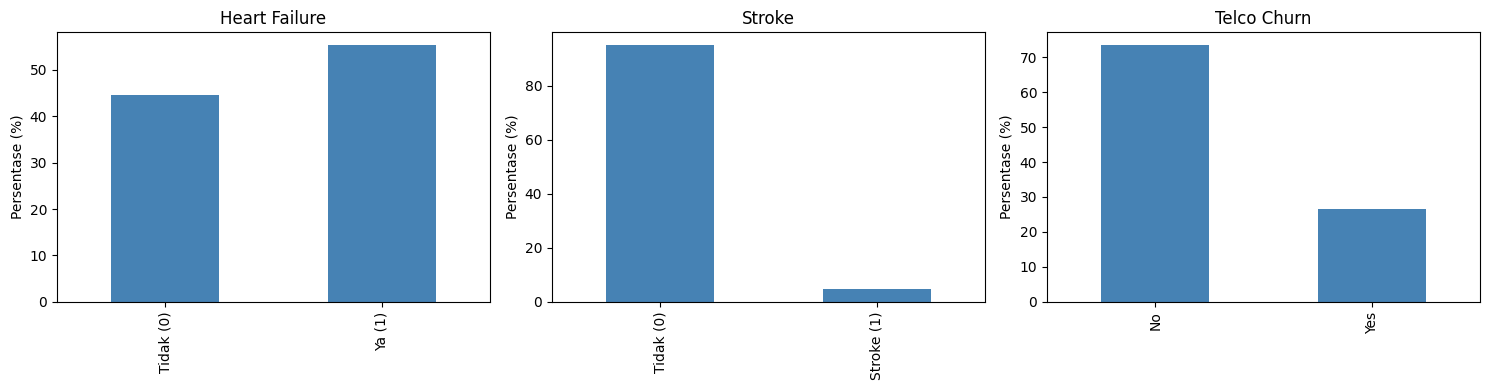

In [5]:
bin_s = pd.DataFrame([rin_heart, rin_stroke, rin_telco]).set_index("Dataset")
bin_s["Valid Biner?"] = bin_s["Jumlah Kelas"] == 2
bin_s["Skor Keseimbangan (%)"] = (bin_s["Kelas Minoritas (%)"] / 50 * 100).round(1)
display(bin_s)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (t, n) in zip(ax, [(tab_heart, "Heart Failure"), (tab_stroke, "Stroke"), (tab_telco, "Telco Churn")]):
    plot_bar(a, t, n)
plt.tight_layout(); plt.show()

In [6]:
valid = bin_s[bin_s["Valid Biner?"]]
print("Dataset yang valid sebagai klasifikasi biner (tepat 2 kelas):", ", ".join(valid.index))
print("Paling seimbang :", valid["Skor Keseimbangan (%)"].idxmax())
print("Paling tidak seimbang :", valid["Skor Keseimbangan (%)"].idxmin())

Dataset yang valid sebagai klasifikasi biner (tepat 2 kelas): Heart Failure, Stroke, Telco Churn
Paling seimbang : Heart Failure
Paling tidak seimbang : Stroke


## Kesimpulan
(Isi setelah melihat output: ketiga dataset 2 kelas; jelaskan mana yang paling seimbang dan mana yang paling timpang berdasarkan persentase kelas minoritas.)

## Daftar Pustaka
- Soriano, F. (2021). *Heart Failure Prediction Dataset*. Kaggle. https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction
- Soriano, F. (2021). *Stroke Prediction Dataset*. Kaggle. https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset
- blastchar. *Telco Customer Churn* (IBM Sample Data Sets). Kaggle. https://www.kaggle.com/datasets/blastchar/telco-customer-churn

*(Tambahkan tanggal akses dan sesuaikan format sitasi dengan ketentuan dosen.)*